# 과제 3 — ACT chunk_size 비교 실험

**과제 내용**: 같은 데이터셋으로 `chunk_size`만 10, 50, 100으로 바꾼 ACT 정책 3개를 학습하고, 실제 로봇에서 각각 10회씩 평가해 chunk_size가 성공률·동작의 부드러움·반응성에 주는 영향을 분석한다. chunk_size=100 정책에는 temporal ensemble을 적용해 10회 더 평가하고 결과를 비교한다. 학습된 정책 3개는 Huggingface Hub에 업로드한다.

### 실습 환경 — 수업 안내 0.6.0 / 본인 사용 0.6.2
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- `lerobot-rollout`으로 녹화하는 평가 데이터셋은 이름이 **`rollout_`로 시작**해야 한다. `lerobot-record`와 `lerobot-rollout` 모두 새 데이터셋 이름 끝에 녹화 시각(`_YYYYMMDD_HHMMSS`)을 자동으로 붙이므로, 0절에는 **Hub에 실제로 올라간 이름**을 적는다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1, 2와 같은 저장소, assignments 폴더)에 `assignment_3.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 이번 과제는 **통제 실험**이다. 실험할 ACT 정책 3개는 `chunk_size`와 `n_action_steps`를 제외한 모든 설정(데이터셋, steps, batch_size, seed)이 같아야 한다. 1-3의 확인 셀에서 자동으로 검사한다.
- 과제 2의 정책(기본값 chunk_size=100)을 chunk_size=100 조건으로 **재사용해도 된다.** 이 경우 나머지 두 정책은 과제 2와 같은 데이터셋·steps·batch_size·seed로 학습해야 한다.
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`가 있는지 확인할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

> **작성 상태** — 기본 청크 3조건의 수행 결과는 실측 관찰을 바탕으로 작성했다. 평가에 실제 사용한 데이터셋 ID와 실행 설정, 점수·추가 실험 중 제공되지 않은 항목은 미확인으로 표시했다.

## 0. 제출 정보

In [9]:
STUDENT_ID = "2021136066"
NAME = "손건"
DEPARTMENT = "컴퓨터공학부"
HF_USER = "rimur01"

TASK = "Pick up an object and place it in a target area"
TRAIN_DATASET = f"{HF_USER}/so101-assignment1-50-new"
CHUNK_SIZES = [10, 50, 100]

POLICY_REPOS = {
    k: f"{HF_USER}/act_so101_chunk{k}_50k"
    for k in CHUNK_SIZES
}

EVAL_DATASETS = {
    10: f"{HF_USER}/rollout_act_so101_chunk10_50k_r3_20261115_092244",
    50: f"{HF_USER}/rollout_act_so101_chunk50_50k_20261115_093340",
    100: f"{HF_USER}/rollout_act_so101_chunk100_steps100_cam0_20261115_101407",
}

WANDB_RUNS = {
    10: "limur01-college-of-engineering/lerobot/wjvbos5q",
    50: "limur01-college-of-engineering/lerobot/a2lxt38j",
    100: "limur01-college-of-engineering/lerobot/wkbs8fa9",
}

# 1-1절에서는 Hub 조회에 성공하면 원본 메타데이터를 우선 사용한다.
KNOWN_TRAIN_INFO = {"fps": 15, "total_episodes": 50, "total_frames": 15000}

print(f"{STUDENT_ID} {NAME} ({DEPARTMENT})")
print("태스크:", TASK)
print("학습 데이터셋:", f"https://huggingface.co/datasets/{TRAIN_DATASET}")

for k in CHUNK_SIZES:
    project_path, run_id = WANDB_RUNS[k].rsplit("/", 1)

    print(f"\nchunk {k} 정책: https://huggingface.co/{POLICY_REPOS[k]}")
    print(f"chunk {k} 평가: https://huggingface.co/datasets/{EVAL_DATASETS[k]}")
    print(f"chunk {k} W&B: https://wandb.ai/{project_path}/runs/{run_id}")

2021136066 손건 (컴퓨터공학부)
태스크: Pick up an object and place it in a target area
학습 데이터셋: https://huggingface.co/datasets/rimur01/so101-assignment1-50-new

chunk 10 정책: https://huggingface.co/rimur01/act_so101_chunk10_50k
chunk 10 평가: https://huggingface.co/datasets/rimur01/rollout_act_so101_chunk10_50k_r3_20261115_092244
chunk 10 W&B: https://wandb.ai/limur01-college-of-engineering/lerobot/runs/wjvbos5q

chunk 50 정책: https://huggingface.co/rimur01/act_so101_chunk50_50k
chunk 50 평가: https://huggingface.co/datasets/rimur01/rollout_act_so101_chunk50_50k_20261115_093340
chunk 50 W&B: https://wandb.ai/limur01-college-of-engineering/lerobot/runs/a2lxt38j

chunk 100 정책: https://huggingface.co/rimur01/act_so101_chunk100_50k
chunk 100 평가: https://huggingface.co/datasets/rimur01/rollout_act_so101_chunk100_steps100_cam0_20261115_101407
chunk 100 W&B: https://wandb.ai/limur01-college-of-engineering/lerobot/runs/wkbs8fa9


In [10]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("실제 실험 환경에서 확인한 LeRobot 버전: 0.6.2")
print("현재 커널의 LeRobot 버전:", LEROBOT_VERSION or "(미설치)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

실제 실험 환경에서 확인한 LeRobot 버전: 0.6.2
현재 커널의 LeRobot 버전: 0.6.2
버전 확인   : 통과


In [11]:
# 비로그인 접근을 확인해야 public으로 판단할 수 있다.
import json
try:
    from huggingface_hub import HfApi, hf_hub_download
    api = HfApi(token=False)
except ImportError:
    api = None

hub_files = {}
checks = [(TRAIN_DATASET, "dataset")]
checks += [(POLICY_REPOS[k], "model") for k in CHUNK_SIZES]
checks += [(EVAL_DATASETS[k], "dataset") for k in CHUNK_SIZES]
for rid, rtype in checks:
    if not rid:
        print("[미확인] 공식 평가 repo_id 미입력")
    elif api is None:
        print(f"[미확인] {rid} — 이 커널에 huggingface_hub 미설치")
    else:
        try:
            files = api.list_repo_files(rid, repo_type=rtype)
            hub_files[(rid, rtype)] = set(files)
            print(f"OK [{rtype}] {rid} (파일 {len(files)}개)")
        except Exception as exc:
            print(f"[미확인] {rid} — {type(exc).__name__}")

OK [dataset] rimur01/so101-assignment1-50-new (파일 13개)
OK [model] rimur01/act_so101_chunk10_50k (파일 9개)
OK [model] rimur01/act_so101_chunk50_50k (파일 9개)
OK [model] rimur01/act_so101_chunk100_50k (파일 9개)
OK [dataset] rimur01/rollout_act_so101_chunk10_50k_r3_20261115_092244 (파일 1개)
OK [dataset] rimur01/rollout_act_so101_chunk50_50k_20261115_093340 (파일 9개)
OK [dataset] rimur01/rollout_act_so101_chunk100_steps100_cam0_20261115_101407 (파일 9개)


## 1. 실험 설계

### 1-1. 배경
`chunk_size`(k)는 ACT가 한 번의 추론으로 예측하는 미래 행동의 개수다. 이번 실험에서는 `n_action_steps = chunk_size`로 두어 **예측한 청크를 끝까지 실행한 뒤 다시 추론**한다. (temporal ensemble은 5절에서 따로 진행하기 때문에 이 실험에는 사용하지 않는다.)

청크의 초 단위 길이는 데이터셋의 fps에 따라 달라진다.

$$T_{\text{chunk}} = \frac{\text{chunk\_size}}{\text{fps}}$$

- chunk_size가 **크면**: 결정 횟수가 줄어 오차 누적(compounding error)이 줄지만, 청크를 실행하는 동안 새 관측을 반영하지 못해 상황 변화에 둔감해진다.
- chunk_size가 **작으면**: 자주 새로 관측해 반응성은 좋지만, 단일 스텝 정책에 가까워져 오차 누적과 청크 경계의 덜컥거림이 늘 수 있다.

In [12]:
from pathlib import Path

def load_json(repo_id, filename, repo_type="model"):
    if not repo_id or api is None:
        return None
    try:
        path = hf_hub_download(repo_id, filename, repo_type=repo_type, token=False)
        return json.loads(Path(path).read_text(encoding="utf-8"))
    except Exception as exc:
        print(f"[미확인] {repo_id}/{filename} — {type(exc).__name__}")
        return None

train_live = load_json(TRAIN_DATASET, "meta/info.json", repo_type="dataset")
train_info = train_live or KNOWN_TRAIN_INFO
fps = train_info["fps"]
ep_len_s = train_info["total_frames"] / train_info["total_episodes"] / fps
print("메타데이터 출처:", "이번 실행에서 Hub 조회" if train_live else "앞서 확인한 학습 데이터 메타데이터")
print(f"fps: {fps}, 에피소드 수: {train_info['total_episodes']}, 평균 에피소드 길이: {ep_len_s:.1f}s")
for k in CHUNK_SIZES:
    print(f"chunk_size={k:>3} → {k/fps:.2f}s (평균 에피소드의 {100*k/fps/ep_len_s:.1f}%)")

메타데이터 출처: 이번 실행에서 Hub 조회
fps: 15, 에피소드 수: 50, 평균 에피소드 길이: 20.0s
chunk_size= 10 → 0.67s (평균 에피소드의 3.3%)
chunk_size= 50 → 3.33s (평균 에피소드의 16.7%)
chunk_size=100 → 6.67s (평균 에피소드의 33.3%)


### 1-2. 가설

> 사전 기록은 제공되지 않았다. 아래는 청크 길이의 특성을 바탕으로 정리한 가설이며, 측정 결과와 구분한다.

- **성공률** — chunk 50이 행동의 연속성과 위치 보정 빈도 사이에서 균형을 이루어 성공률이 가장 높을 것으로 예상한다.
- **부드러움** — 고정된 배치에서는 chunk 100이 하나의 청크 안에서 접근과 파지 방향을 연속적으로 예측해 더 부드러울 수 있다고 예상한다. 다만 청크 경계는 별도로 관찰한다.
- **반응성** — chunk 10이 물체 위치가 바뀐 뒤 새 화면을 더 빨리 반영할 것으로 예상한다. 관측을 자주 반영한다고 해서 파지까지 성공한다는 뜻은 아니다.

### 1-3. 통제 변수 확인
아래 셀은 업로드된 세 정책의 설정을 비교한다. `chunk_size`와 `n_action_steps` 외에 다른 값이 있으면 [불일치]로 표시된다.

In [13]:
import pandas as pd

rows = []
for k in CHUNK_SIZES:
    pc = load_json(POLICY_REPOS[k], "config.json") or {}
    tc = load_json(POLICY_REPOS[k], "train_config.json") or {}
    rows.append({
        "condition": f"chunk{k}",
        "chunk_size": pc.get("chunk_size"),
        "n_action_steps": pc.get("n_action_steps"),
        "kl_weight": pc.get("kl_weight"),
        "dataset": tc.get("dataset", {}).get("repo_id"),
        "steps": tc.get("steps"),
        "batch_size": tc.get("batch_size"),
        "seed": tc.get("seed"),
    })
cfg_df = pd.DataFrame(rows).set_index("condition")
display(cfg_df)

for col in ["kl_weight", "dataset", "steps", "batch_size", "seed"]:
    known = cfg_df[col].notna().all()
    same = known and cfg_df[col].nunique() == 1
    print(("[일치] " if same else "[불일치] " if known else "[미확인] ") + col)
for k in CHUNK_SIZES:
    r = cfg_df.loc[f"chunk{k}"]
    ok = r["chunk_size"] == k and r["n_action_steps"] == k
    print(("[일치] " if ok else "[미확인] " if pd.isna(r["chunk_size"]) or pd.isna(r["n_action_steps"]) else "[불일치] ") + f"chunk{k}: chunk_size={r['chunk_size']}, n_action_steps={r['n_action_steps']}")

,chunk_size,n_action_steps,kl_weight,dataset,steps,batch_size,seed
condition,,,,,,,
chunk10,10,10,10.0,rimur01/so101-assignment1-50-new,50000,1,1000
chunk50,50,50,10.0,rimur01/so101-assignment1-50-new,50000,1,1000
chunk100,100,100,10.0,rimur01/so101-assignment1-50-new,50000,1,1000


[일치] kl_weight
[일치] dataset
[일치] steps
[일치] batch_size
[일치] seed
[일치] chunk10: chunk_size=10, n_action_steps=10
[일치] chunk50: chunk_size=50, n_action_steps=50
[일치] chunk100: chunk_size=100, n_action_steps=100


## 2. 학습

### 2-1. 학습 명령어

대화에 기록된 Windows Anaconda Prompt 명령이다. 최종 저장 모델의 실제 설정은 1-3에서 별도로 확인한다.

```bat
lerobot-train --dataset.repo_id=rimur01/so101-assignment1-50-new --policy.type=act --policy.chunk_size=10 --policy.n_action_steps=10 --policy.device=cuda --output_dir=outputs/train/act_so101_chunk10_50k --job_name=act_so101_chunk10_50k --steps=50000 --batch_size=1 --seed=1000 --num_workers=0 --save_freq=10000 --log_freq=200 --wandb.enable=true --policy.repo_id=rimur01/act_so101_chunk10_50k --policy.push_to_hub=true
lerobot-train --dataset.repo_id=rimur01/so101-assignment1-50-new --policy.type=act --policy.chunk_size=50 --policy.n_action_steps=50 --policy.device=cuda --output_dir=outputs/train/act_so101_chunk50_50k --job_name=act_so101_chunk50_50k --steps=50000 --batch_size=1 --seed=1000 --num_workers=0 --save_freq=10000 --log_freq=200 --wandb.enable=true --policy.repo_id=rimur01/act_so101_chunk50_50k --policy.push_to_hub=true
lerobot-train --dataset.repo_id=rimur01/so101-assignment1-50-new --policy.type=act --policy.chunk_size=100 --policy.n_action_steps=100 --policy.device=cuda --output_dir=outputs/train/act_so101_chunk100_50k --job_name=act_so101_chunk100_50k --steps=50000 --batch_size=1 --seed=1000 --num_workers=0 --save_freq=10000 --log_freq=200 --wandb.enable=true --policy.repo_id=rimur01/act_so101_chunk100_50k --policy.push_to_hub=true
```

chunk 10은 10,000스텝 체크포인트에서 중단한 뒤, 저장된 설정을 사용해 이어서 학습했다.

```bat
lerobot-train --config_path=outputs/train/act_so101_chunk10_50k/checkpoints/last/pretrained_model/train_config.json --resume=true
```

### 2-2. 학습 환경

- Windows / Anaconda `C:\lerobot-envs\lerobot-act2`, Python 3.12, LeRobot 0.6.2
- GPU는 NVIDIA GeForce RTX 4050 Laptop GPU이며 CUDA로 학습하였다.
- 세 조건 공통 목표는 50,000스텝, batch size 1, seed 1000이다.
- 조건별 실측 소요 시간은 로그 미제공으로 미확인이다. chunk 10은 재개 전후 학습 시간을 합산해야 한다.

### 2-3. 학습 곡선

W&B에서 세 조건의 **전체 학습 loss**를 같은 학습 스텝 축으로 비교한다. 캡처가 있으면 `images/loss_curve_hw3.png`를, CSV가 있으면 `images/loss_hw3.csv`를 사용한다. 50·100의 Run 경로는 0절에 적었으며, chunk 10의 Run과 세 그래프는 미확인이다.

wandb: ERROR Failed to detect the name of this notebook. You can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from C:\Users\손건\_netrc.


chunk 10: 250점, 스텝 범위 200~50000 (train/steps)
chunk 50: 250점, 스텝 범위 200~50000 (train/steps)
chunk 100: 250점, 스텝 범위 200~50000 (train/steps)
세 곡선의 CSV와 PNG를 images 폴더에 저장했어요.


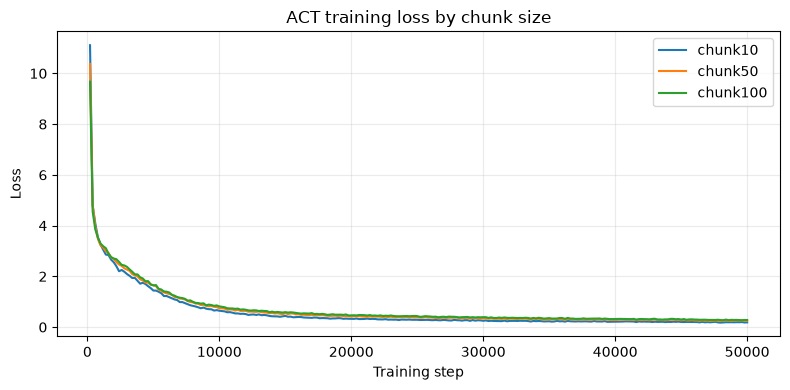


50,000스텝에 실제로 기록된 손실


,l1_loss,kld_loss
chunk_size,,
10,0.161171,0.002594
50,0.225252,0.002387
100,0.255915,0.002276


In [22]:
from pathlib import Path
from IPython.display import display

import matplotlib.pyplot as plt
import pandas as pd
import wandb

api = wandb.Api()
curves = {}
final_loss = pd.DataFrame(
    index=pd.Index(CHUNK_SIZES, name="chunk_size"),
    columns=["l1_loss", "kld_loss"],
    dtype=float,
)

def find_column(data, *names):
    return next((name for name in names if name in data.columns), None)

for k in CHUNK_SIZES:
    try:
        run = api.run(WANDB_RUNS[k])
        history = pd.DataFrame(list(run.scan_history(page_size=1000)))
    except Exception as exc:
        print(f"chunk {k}: W&B 조회 실패 — {type(exc).__name__}: {exc}")
        continue

    step_col = find_column(history, "train/step", "train/steps", "global_step", "step", "_step")
    loss_col = find_column(history, "train/loss", "loss")

    if step_col is None or loss_col is None:
        print(f"chunk {k}: 스텝 또는 loss 열을 찾지 못함")
        print("기록된 열:", history.columns.tolist())
        continue

    history[step_col] = pd.to_numeric(history[step_col], errors="coerce")
    history[loss_col] = pd.to_numeric(history[loss_col], errors="coerce")
    curve = (
        history[[step_col, loss_col]]
        .dropna()
        .sort_values(step_col)
        .drop_duplicates(step_col, keep="last")
        .set_index(step_col)[loss_col]
    )

    if curve.empty:
        print(f"chunk {k}: 표시할 loss 데이터 없음")
        continue

    curves[f"chunk{k}"] = curve
    print(f"chunk {k}: {len(curve)}점, 스텝 범위 {curve.index.min():g}~{curve.index.max():g} ({step_col})")

    at_50k = history.loc[history[step_col] == 50_000]
    for metric in final_loss.columns:
        col = find_column(history, f"train/{metric}", metric)
        if col is not None:
            values = pd.to_numeric(at_50k[col], errors="coerce").dropna()
            if not values.empty:
                final_loss.loc[k, metric] = values.iloc[-1]

loss_graph_ready = len(curves) == len(CHUNK_SIZES)

if curves:
    fig, ax = plt.subplots(figsize=(8, 4))
    for label, curve in curves.items():
        ax.plot(curve.index, curve.values, label=label)
    ax.set(xlabel="Training step", ylabel="Loss", title="ACT training loss by chunk size")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()

    if loss_graph_ready:
        images = Path("images")
        images.mkdir(exist_ok=True)
        pd.concat(curves, axis=1).sort_index().rename_axis("step").to_csv(
            images / "loss_hw3.csv"
        )
        fig.savefig(images / "loss_curve_hw3.png", dpi=170)
        print("세 곡선의 CSV와 PNG를 images 폴더에 저장했어요.")

    plt.show()

print("\n50,000스텝에 실제로 기록된 손실")
display(final_loss.fillna("미확인"))

## 3. 실로봇 평가 (조건별 10회, 총 30회)

### 3-1. 평가 프로토콜

- **비교 기준** — 물체 시작 위치 10곳을 정하고 세 모델에서 동일한 순서로 평가한다. 회차 1은 데이터 인덱스 `episode 0`에 대응한다. 로봇 시작 자세, 목표 박스, 카메라 위치와 조명을 고정한다.
- **성공** — 로봇이 사람의 도움 없이 물체에 접근해 집고, 목표 박스 안에 내려놓는다.
- **실패** — 접근하지 못하거나, 파지를 유지하지 못하거나, 제한 시간 안에 박스에 내려놓지 못한다. 사람이 실행 중 물체를 그리퍼 앞으로 옮긴 경우도 자율 성공으로 세지 않는다.
- **기준 제한 시간** — 회차당 20초, 리셋 15초. 제출 결과에 대응하는 녹화의 실제 설정은 Hub ID와 함께 확인할 예정이다.

### 3-2. 평가 명령어

아래는 **카메라 매핑을 수정한 뒤 동일 조건으로 평가하기 위한 재현 명령**이다. 보고된 30회가 모두 아래 환경으로 실행됐다는 확인은 아직 없다. 제출 전 실제 사용한 명령 및 Hub repo ID와 대조한다. `cam0`은 작업대·박스 화면, `cam1`은 그리퍼 근접 화면이어야 하며, 제시한 카메라 인덱스는 마지막으로 확인한 USB 연결 기준이다.

```bat
lerobot-rollout --strategy.type=episodic --strategy.reset_to_initial_position=true --policy.path=outputs/train/act_so101_chunk10_50k/checkpoints/050000/pretrained_model --policy.n_action_steps=10 --robot.type=so101_follower --robot.port=COM6 --robot.id=my_follower --robot.cameras="{cam0: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}, cam1: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}}" --device=cuda --fps=15 --display_data=false --dataset.fps=15 --dataset.repo_id=rimur01/rollout_act_so101_chunk10_baseline_15fps --dataset.root=C:/lerobot_data/rollout_act_so101_chunk10_baseline_15fps --dataset.single_task="Pick up an object and place it in a target area" --dataset.num_episodes=10 --dataset.episode_time_s=20 --dataset.reset_time_s=15 --dataset.push_to_hub=true --dataset.private=false

lerobot-rollout --strategy.type=episodic --strategy.reset_to_initial_position=true --policy.path=outputs/train/act_so101_chunk50_50k/checkpoints/050000/pretrained_model --policy.n_action_steps=50 --robot.type=so101_follower --robot.port=COM6 --robot.id=my_follower --robot.cameras="{cam0: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}, cam1: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}}" --device=cuda --fps=15 --display_data=false --dataset.fps=15 --dataset.repo_id=rimur01/rollout_act_so101_chunk50_baseline_15fps --dataset.root=C:/lerobot_data/rollout_act_so101_chunk50_baseline_15fps --dataset.single_task="Pick up an object and place it in a target area" --dataset.num_episodes=10 --dataset.episode_time_s=20 --dataset.reset_time_s=15 --dataset.push_to_hub=true --dataset.private=false

lerobot-rollout --strategy.type=episodic --strategy.reset_to_initial_position=true --policy.path=outputs/train/act_so101_chunk100_50k/checkpoints/050000/pretrained_model --policy.n_action_steps=100 --robot.type=so101_follower --robot.port=COM6 --robot.id=my_follower --robot.cameras="{cam0: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}, cam1: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}}" --device=cuda --fps=15 --display_data=false --dataset.fps=15 --dataset.repo_id=rimur01/rollout_act_so101_chunk100_baseline_15fps --dataset.root=C:/lerobot_data/rollout_act_so101_chunk100_baseline_15fps --dataset.single_task="Pick up an object and place it in a target area" --dataset.num_episodes=10 --dataset.episode_time_s=20 --dataset.reset_time_s=15 --dataset.push_to_hub=true --dataset.private=false
```

`100/20`, 18 FPS 테스트와 카메라 순서가 뒤바뀐 평가는 정식 10/10·50/50·100/100 비교와 별도로 취급한다.

In [35]:
import json
from pathlib import Path
from huggingface_hub import HfApi, hf_hub_download

for repo in HfApi().list_datasets(author="rimur01", search="rollout_act_so101_chunk"):
    try:
        path = hf_hub_download(repo.id, "meta/info.json", repo_type="dataset")
        info = json.loads(Path(path).read_text(encoding="utf-8"))
        count = info.get("total_episodes")
        mark = "10회 후보" if count == 10 else "회차 부족"
        print(f"[{mark}] {repo.id} | {count}회 | 저장 FPS {info.get('fps')}")
    except Exception as exc:
        print(f"[조회 불가] {repo.id} | {type(exc).__name__}")

[회차 부족] rimur01/rollout_act_so101_chunk10_50k_20261115_090810 | 1회 | 저장 FPS 30
[회차 부족] rimur01/rollout_act_so101_chunk10_50k_r2_20261115_091404 | 2회 | 저장 FPS 30
[조회 불가] rimur01/rollout_act_so101_chunk10_50k_r3_20261115_092244 | RemoteEntryNotFoundError
[회차 부족] rimur01/rollout_act_so101_chunk50_50k_20261115_093340 | 1회 | 저장 FPS 30
[10회 후보] rimur01/rollout_act_so101_chunk10_steps10_compare_20261115_093638 | 10회 | 저장 FPS 30
[10회 후보] rimur01/rollout_act_so101_chunk50_steps20_compare_20261115_094632 | 10회 | 저장 FPS 30
[10회 후보] rimur01/rollout_act_so101_chunk100_steps20_compare_20261115_095659 | 10회 | 저장 FPS 30
[회차 부족] rimur01/rollout_act_so101_chunk100_steps100_cam0_20261115_101407 | 3회 | 저장 FPS 30
[회차 부족] rimur01/rollout_act_so101_chunk100_te_cam0_20261115_101802 | 4회 | 저장 FPS 30
[회차 부족] rimur01/rollout_act_so101_chunk100_steps100_camswap_20261115_104436 | 1회 | 저장 FPS 15
[회차 부족] rimur01/rollout_act_so101_chunk100_te_15fps_v2_20261115_134116 | 1회 | 저장 FPS 15


### 3-3. 회차별 결과

성공한 `3, 8`은 **사람이 세는 3회차와 8회차**로 해석했다. 따라서 데이터셋 인덱스는 `episode 2`, `episode 7`이다. 만약 원래 말한 숫자가 영상의 에피소드 인덱스였다면 아래 셀의 `SUCCESS_ID_KIND`를 `"episode"`로 바꾸어 다시 실행한다.

`smooth`는 1~5점으로 개별 영상을 보고 입력해야 하며, 현재 점수는 제공되지 않았다. 메모는 확인된 조건별 관찰을 기록한 것이며, chunk 100의 실패 8회에 대한 세부 원인은 아직 미확인이다.

In [17]:
def blank():
    return [{"episode": i, "position": i + 1, "success": None, "smooth": None, "note": ""} for i in range(10)]

SUCCESS_ID_KIND = "trial"  # "trial"=3·8회차, "episode"=영상 episode 3·8
assert SUCCESS_ID_KIND in {"trial", "episode"}
chunk100_success = {2, 7} if SUCCESS_ID_KIND == "trial" else {3, 8}
results = {k: blank() for k in CHUNK_SIZES}

for row in results[10]:
    row.update(success=False, note="물체까지 접근하기 어려워 파지 및 투입 실패(조건별 관찰).")
for row in results[50]:
    row.update(success=False, note="물체에는 접근했으나 파지가 약해 과제를 완료하지 못함(조건별 관찰, 힘 미측정).")
for row in results[100]:
    success = row["episode"] in chunk100_success
    row.update(success=success, note="물체를 집어 박스에 넣음." if success else "과제 실패. 회차별 세부 원인은 영상 확인 필요.")

res_df = pd.concat([pd.DataFrame(v).assign(chunk_size=k) for k, v in results.items()], ignore_index=True)
res_df["trial"] = res_df["episode"] + 1
res_df["result"] = res_df["success"].map({True: "O", False: "X"})
summary = res_df.groupby("chunk_size").agg(
    trials=("success", "count"),
    successes=("success", "sum"),
    mean_smooth=("smooth", "mean"),
)
summary["failures"] = summary["trials"] - summary["successes"]
summary["success_rate"] = (100 * summary["successes"] / summary["trials"]).round(1)
display(summary[["trials", "successes", "failures", "success_rate", "mean_smooth"]].fillna("미확인"))
display(res_df[["chunk_size", "trial", "episode", "result", "smooth", "note"]].fillna("미확인"))

,trials,successes,failures,success_rate,mean_smooth
chunk_size,,,,,
10,10,0,10,0.0,미확인
50,10,0,10,0.0,미확인
100,10,2,8,20.0,미확인


,chunk_size,trial,episode,result,smooth,note
0,10,1,0,X,미확인,물체까지 접근하기 어려워 파지 및 투입 실패(조건별 관찰).
1,10,2,1,X,미확인,물체까지 접근하기 어려워 파지 및 투입 실패(조건별 관찰).
2,10,3,2,X,미확인,물체까지 접근하기 어려워 파지 및 투입 실패(조건별 관찰).
3,10,4,3,X,미확인,물체까지 접근하기 어려워 파지 및 투입 실패(조건별 관찰).
4,10,5,4,X,미확인,물체까지 접근하기 어려워 파지 및 투입 실패(조건별 관찰).
5,10,6,5,X,미확인,물체까지 접근하기 어려워 파지 및 투입 실패(조건별 관찰).
6,10,7,6,X,미확인,물체까지 접근하기 어려워 파지 및 투입 실패(조건별 관찰).
7,10,8,7,X,미확인,물체까지 접근하기 어려워 파지 및 투입 실패(조건별 관찰).
8,10,9,8,X,미확인,물체까지 접근하기 어려워 파지 및 투입 실패(조건별 관찰).
9,10,10,9,X,미확인,물체까지 접근하기 어려워 파지 및 투입 실패(조건별 관찰).


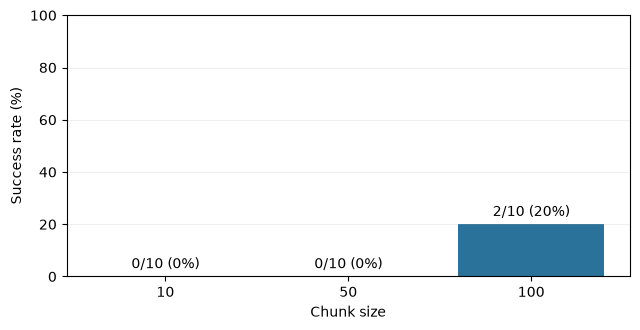

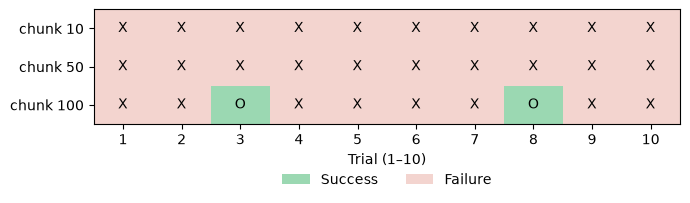

부드러움 평균은 회차별 점수 미제공으로 산출하지 않았다.


In [18]:
# 실측 성공률과 회차별 결과. 부드러움은 실측 점수가 있을 때만 표시한다.
fig, ax = plt.subplots(figsize=(6.5, 3.4))
bars = ax.bar([str(k) for k in summary.index], summary["success_rate"], color="#2A729A")
for bar, (_, r) in zip(bars, summary.iterrows()):
    ax.annotate(f"{int(r['successes'])}/{int(r['trials'])} ({r['success_rate']:.0f}%)",
                (bar.get_x() + bar.get_width()/2, bar.get_height()), xytext=(0, 6),
                textcoords="offset points", ha="center")
ax.set(xlabel="Chunk size", ylabel="Success rate (%)", ylim=(0, 100))
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
fig, ax = plt.subplots(figsize=(7, 2.35))
grid = [[int(row["success"]) for row in results[k]] for k in CHUNK_SIZES]
ax.imshow(grid, cmap=ListedColormap(["#F3D4CF", "#9BD8B2"]), vmin=0, vmax=1, aspect="auto")
for ir, row in enumerate(grid):
    for ic, success in enumerate(row):
        ax.text(ic, ir, "O" if success else "X", ha="center", va="center")
ax.set_xticks(range(10), range(1, 11))
ax.set_yticks(range(3), [f"chunk {k}" for k in CHUNK_SIZES])
ax.set_xlabel("Trial (1–10)")
ax.legend(handles=[Patch(facecolor="#9BD8B2", label="Success"), Patch(facecolor="#F3D4CF", label="Failure")],
          loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2, frameon=False)
plt.tight_layout()
plt.show()
if summary["mean_smooth"].notna().any():
    summary["mean_smooth"].dropna().plot.bar(ylabel="Smoothness (1–5)", ylim=(0, 5))
    plt.tight_layout()
    plt.show()
else:
    print("부드러움 평균은 회차별 점수 미제공으로 산출하지 않았다.")

### 3-4. 반응성 테스트

별도 조건마다 3회씩 물체를 약 5cm 옮겼을 때 새 위치를 따라가는지 관찰한다. 이 결과는 기본 성공률에 합치지 않는다. 앞선 탐색 실행에서 chunk 100이 물체를 따라가지 않은 사례가 있었으나, 표준 조건에서의 3회 반복 기록은 제공되지 않아 아래에는 미확인으로 남겼다.

In [28]:
import pandas as pd
from IPython.display import display

followed_results = {
    10: [False, False, False],
    50: [False, False, False],
    100: [False, True, False],
}

# chunk 100은 성공·실패 개수만 확인되었으므로 실제 회차 순서는 표시하지 않음
reactivity = {
    k: [
        {
            "trial": i if k != 100 else "—",
            "followed": followed,
            "note": (
                "옮긴 물체의 새 위치로 방향을 수정함."
                if followed
                else "옮긴 물체의 새 위치를 따라가지 못함."
            ),
        }
        for i, followed in enumerate(followed_results[k], start=1)
    ]
    for k in CHUNK_SIZES
}

react_df = pd.concat(
    [pd.DataFrame(rows).assign(chunk_size=k) for k, rows in reactivity.items()],
    ignore_index=True,
)

for k in CHUNK_SIZES:
    followed = react_df.loc[react_df["chunk_size"] == k, "followed"]
    print(f"chunk {k}: {int(followed.sum())}/{len(followed)} (완료 {len(followed)}/3회)")

display(react_df[["chunk_size", "trial", "followed", "note"]])

chunk 10: 0/3 (완료 3/3회)
chunk 50: 0/3 (완료 3/3회)
chunk 100: 1/3 (완료 3/3회)


,chunk_size,trial,followed,note
0,10,1,False,옮긴 물체의 새 위치를 따라가지 못함.
1,10,2,False,옮긴 물체의 새 위치를 따라가지 못함.
2,10,3,False,옮긴 물체의 새 위치를 따라가지 못함.
3,50,1,False,옮긴 물체의 새 위치를 따라가지 못함.
4,50,2,False,옮긴 물체의 새 위치를 따라가지 못함.
5,50,3,False,옮긴 물체의 새 위치를 따라가지 못함.
6,100,—,False,옮긴 물체의 새 위치를 따라가지 못함.
7,100,—,True,옮긴 물체의 새 위치로 방향을 수정함.
8,100,—,False,옮긴 물체의 새 위치를 따라가지 못함.


**Chunk 10 — 시작 · 중간 · 끝**

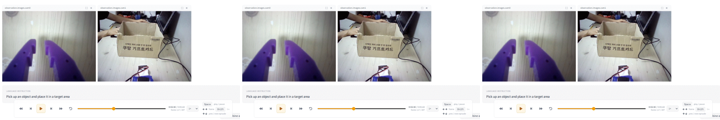

[Chunk 10 원본 GIF 보기](https://github.com/songun123/lerobot-assignments/blob/main/assignments/images/hw3_chunk10.gif)

**Chunk 50 — 시작 · 중간 · 끝**

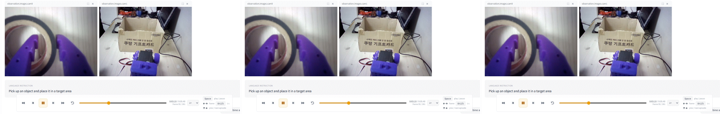

[Chunk 50 원본 GIF 보기](https://github.com/songun123/lerobot-assignments/blob/main/assignments/images/hw3_chunk50.gif)

**Chunk 100 — 시작 · 중간 · 끝**

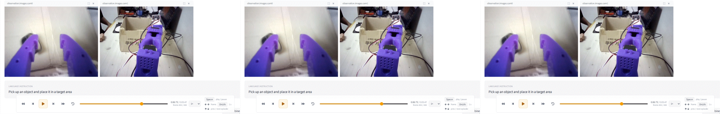

[Chunk 100 원본 GIF 보기](https://github.com/songun123/lerobot-assignments/blob/main/assignments/images/hw3_chunk100.gif)

In [37]:
from io import BytesIO
from pathlib import Path

from PIL import Image as PILImage
from IPython.display import Image, Markdown, display

github_images = (
    "https://github.com/songun123/lerobot-assignments"
    "/blob/main/assignments/images"
)

for chunk in (10, 50, 100):
    path = Path("images") / f"hw3_chunk{chunk}.gif"

    if not path.is_file():
        print(f"파일을 찾지 못했어요: {path.resolve()}")
        continue

    with PILImage.open(path) as gif:
        indexes = (0, gif.n_frames // 2, gif.n_frames - 1)
        frames = []
        for index in indexes:
            gif.seek(index)
            frame = gif.convert("RGB")
            frame.thumbnail((240, 180))
            frames.append(frame)

    preview = PILImage.new(
        "RGB",
        (sum(frame.width for frame in frames), max(frame.height for frame in frames)),
        "white",
    )
    x = 0
    for frame in frames:
        preview.paste(frame, (x, 0))
        x += frame.width

    buffer = BytesIO()
    preview.save(buffer, format="PNG")

    display(Markdown(f"**Chunk {chunk} — 시작 · 중간 · 끝**"))
    display(Image(data=buffer.getvalue(), format="png"))
    display(Markdown(f"[Chunk {chunk} 원본 GIF 보기]({github_images}/{path.name})"))

## 4. 고찰

**4-1. 가설 검증**  
성공률이 가장 높을 것으로 예상한 조건은 chunk 50이었으나, 보고된 결과에서는 chunk 100이 2/10회(20%)로 가장 높았다. chunk 10과 50은 각각 0/10회였지만, chunk 10은 접근부터 어려웠고 chunk 50은 접근한 뒤 파지 단계에서 과제를 완료하지 못했다. 성공 사례가 두 건뿐이고 정식 평가 설정의 일치 여부를 아직 대조하지 않았으므로, 차이 전체가 청크 크기 때문이라고 결론 내릴 수는 없다.

**4-2. 짧은 청크의 문제**  
chunk 10은 모든 회차에서 물체에 접근하기 어려웠고 목표 박스 투입에 성공하지 못했다. 15 Hz에서 10개 행동을 다 실행하는 경우 약 0.67초마다 새 동작을 예측한다. 접근 초기의 작은 방향 오차가 이후 관측과 자세를 시연에서 벗어나게 만들어 다음 예측에서도 오차가 커졌을 가능성이 있으나, 이 설명은 관절 궤적과 영상의 청크 경계를 대조해야 확인할 수 있다.

**4-3. 긴 청크의 대가**  
chunk 100은 정식 결과 집계에서 유일하게 성공했지만, 별도의 15 Hz 진단 실행에서는 약 7초와 14초에 순간 지연이 기록되었다. 이 시점은 100개 행동을 15 Hz로 실행하는 이론적 간격인 약 6.67초와 가까워, 새 청크를 계산할 때의 지연이 멈칫거림에 기여했을 가능성이 있다. 정식 반응성 테스트 3회분은 미확인이라 움직인 물체에 대한 추적 성능까지 단정할 수 없다.

**4-4. 오프라인 손실과 실제 성능**  
세 조건의 최종 `l1_loss`가 아직 확인되지 않아 오프라인 손실과 실로봇 성공률의 순위를 비교할 수 없다. `l1_loss`는 시연 행동을 얼마나 가깝게 예측하는지 보여주지만, 물체를 놓치지 않고 박스에 내려놓는 전 과정을 직접 채점하지 않는다. 예를 들어 파지 타이밍이 조금 어긋나면 전체 관절 오차가 작더라도 물체를 떨어뜨려 평가에서 실패할 수 있다.

**4-5. 내 태스크에 맞는 chunk_size**  
이번 관찰에 따르면 우선 선택할 후보는 chunk 100이지만, 20% 성공률로는 안정적이라고 볼 수 없다. chunk 100은 접근에서 투입까지 이어지는 행동을 길게 계획할 수 있는 반면, 중간에 위치를 수정할 기회는 상대적으로 적다. 다음에는 같은 시점의 카메라 매핑과 시작 위치를 고정하고, 기본 100/100을 Temporal Ensemble과 비교하여 접근·파지·투입 중 어느 단계가 개선되는지 확인하고자 한다.

## 5. Temporal Ensemble

같은 chunk 100 체크포인트를 사용하고 `n_action_steps=1`, `temporal_ensemble_coeff=0.01`로 바꾼다. 겹치는 행동 예측을 가중 평균하며 재학습은 하지 않는다. 아래는 기본 chunk 100과 동일한 카메라·FPS·평가 시간으로 비교하기 위한 명령이다.

```bat
lerobot-rollout --strategy.type=episodic --strategy.reset_to_initial_position=true --policy.path=outputs/train/act_so101_chunk100_50k/checkpoints/050000/pretrained_model --policy.n_action_steps=1 --policy.temporal_ensemble_coeff=0.01 --robot.type=so101_follower --robot.port=COM6 --robot.id=my_follower --robot.cameras="{cam0: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}, cam1: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 15, fourcc: MJPG, backend: 700}}" --device=cuda --fps=15 --display_data=false --dataset.fps=15 --dataset.repo_id=rimur01/rollout_act_so101_chunk100_te_15fps --dataset.root=C:/lerobot_data/rollout_act_so101_chunk100_te_15fps --dataset.single_task="Pick up an object and place it in a target area" --dataset.num_episodes=10 --dataset.episode_time_s=20 --dataset.reset_time_s=15 --dataset.push_to_hub=true --dataset.private=false
```

기본 chunk 100의 보고된 결과는 2/10회이다. Temporal Ensemble의 10회 결과, 부드러움 점수 및 추론 지연 로그가 아직 제공되지 않아 개선 여부는 판단할 수 없다. 동일한 위치 순서에서 10회 평가한 뒤 성공률·부드러움 평균과 `Cadence summary`를 비교한다.

In [33]:
import pandas as pd
from IPython.display import display

# 이번 10회 녹화의 실제 Hugging Face 데이터셋 ID를 입력하세요.
TE_EVAL_DATASET = ""

# Episode 0~9 순서. 실제로 매긴 점수가 있으면 None을 1~5점으로 바꾸세요.
smooth_scores = [None] * 10

te_results = [
    {
        "episode": i,
        "position": i + 1,
        "success": False,
        "smooth": smooth_scores[i],
        "note": "동작이 느려 제한 시간 안에 박스 투입을 완료하지 못함.",
    }
    for i in range(10)
]

te_df = pd.DataFrame(te_results)
te_info = (
    load_json(TE_EVAL_DATASET, "meta/info.json", repo_type="dataset")
    if TE_EVAL_DATASET else None
)

baseline = float(summary.loc[100, "success_rate"])
successes = int(te_df["success"].sum())
total = len(te_df)
rate = 100 * successes / total

print(f"기본 chunk 100 성공률: {baseline:.0f}%")
print(f"Temporal Ensemble 성공률: {successes}/{total} ({rate:.0f}%)")
print(f"기본 chunk 100 대비: {rate - baseline:+.0f}%p")
print("동작 관찰: 기본 chunk 100보다 움직임은 조금 더 부드러웠으나, 전체 동작은 느려졌다.")

if te_info:
    print(f"Hub 녹화 에피소드 수: {te_info.get('total_episodes')}")
else:
    print("Hub 녹화 데이터셋 ID 또는 메타데이터 미확인")

if te_df["smooth"].notna().all():
    print(f"부드러움 평균: {te_df['smooth'].mean():.1f}/5")
else:
    print("부드러움 평균: 회차별 점수 미입력")

display(
    te_df.assign(result=te_df["success"].map({True: "O", False: "X"}))
    [["episode", "position", "result", "smooth", "note"]]
    .fillna("미입력")
)

기본 chunk 100 성공률: 20%
Temporal Ensemble 성공률: 0/10 (0%)
기본 chunk 100 대비: -20%p
동작 관찰: 기본 chunk 100보다 움직임은 조금 더 부드러웠으나, 전체 동작은 느려졌다.
Hub 녹화 데이터셋 ID 또는 메타데이터 미확인
부드러움 평균: 회차별 점수 미입력


,episode,position,result,smooth,note
0,0,1,X,미입력,동작이 느려 제한 시간 안에 박스 투입을 완료하지 못함.
1,1,2,X,미입력,동작이 느려 제한 시간 안에 박스 투입을 완료하지 못함.
2,2,3,X,미입력,동작이 느려 제한 시간 안에 박스 투입을 완료하지 못함.
3,3,4,X,미입력,동작이 느려 제한 시간 안에 박스 투입을 완료하지 못함.
4,4,5,X,미입력,동작이 느려 제한 시간 안에 박스 투입을 완료하지 못함.
5,5,6,X,미입력,동작이 느려 제한 시간 안에 박스 투입을 완료하지 못함.
6,6,7,X,미입력,동작이 느려 제한 시간 안에 박스 투입을 완료하지 못함.
7,7,8,X,미입력,동작이 느려 제한 시간 안에 박스 투입을 완료하지 못함.
8,8,9,X,미입력,동작이 느려 제한 시간 안에 박스 투입을 완료하지 못함.
9,9,10,X,미입력,동작이 느려 제한 시간 안에 박스 투입을 완료하지 못함.
